In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("healthcare_dataset.csv")

In [3]:
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [4]:
df.shape

(55500, 15)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  object 
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  object 
 3   Blood Type          55500 non-null  object 
 4   Medical Condition   55500 non-null  object 
 5   Date of Admission   55500 non-null  object 
 6   Doctor              55500 non-null  object 
 7   Hospital            55500 non-null  object 
 8   Insurance Provider  55500 non-null  object 
 9   Billing Amount      55500 non-null  float64
 10  Room Number         55500 non-null  int64  
 11  Admission Type      55500 non-null  object 
 12  Discharge Date      55500 non-null  object 
 13  Medication          55500 non-null  object 
 14  Test Results        55500 non-null  object 
dtypes: float64(1), int64(2), object(12)
memory usage: 6.4

In [6]:
#missing value check
df.isnull().sum()

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64

In [7]:
#percentage check
(df.isnull().sum() / len(df))*100

Name                  0.0
Age                   0.0
Gender                0.0
Blood Type            0.0
Medical Condition     0.0
Date of Admission     0.0
Doctor                0.0
Hospital              0.0
Insurance Provider    0.0
Billing Amount        0.0
Room Number           0.0
Admission Type        0.0
Discharge Date        0.0
Medication            0.0
Test Results          0.0
dtype: float64

In [8]:
df.duplicated().sum()

np.int64(534)

In [9]:
df.describe()

,Age,Billing Amount,Room Number
count,55500.000000,55500.000000,55500.000000
mean,51.539459,25539.316097,301.134829
std,19.602454,14211.454431,115.243069
min,13.000000,-2008.492140,101.000000
25%,35.000000,13241.224652,202.000000
50%,52.000000,25538.069376,302.000000
75%,68.000000,37820.508436,401.000000
max,89.000000,52764.276736,500.000000


In [10]:
# Isse numerical columns ki basic statistics milengi:
# - count – Total records
# - mean – Average
# - std – Standard deviation
# - min – Minimum value
# - max – Maximum value
# - 25%, 50%, 75% – Quartiles

In [11]:
#categorical data  summary
df.describe(include="object")


,Name,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Admission Type,Discharge Date,Medication,Test Results
count,55500,55500,55500,55500,55500,55500,55500,55500,55500,55500,55500,55500
unique,49992,2,8,6,1827,40341,39876,5,3,1856,5,3
top,DAvId muNoZ,Male,A-,Arthritis,2024-03-16,Michael Smith,LLC Smith,Cigna,Elective,2020-03-15,Lipitor,Abnormal
freq,3,27774,6969,9308,50,27,44,11249,18655,53,11140,18627


In [12]:
#data cleaning -duplicate record 
# df.copy() original dataset ko safe rakhta hai aur hum cleaning copy par karte hain.

In [13]:
df_clean = df.copy()
df_clean.drop_duplicates(inplace = True)


In [14]:
df_clean.shape

(54966, 15)

In [15]:
df_clean.column = df_clean.columns.str.strip()

C:\Users\Ishika\AppData\Local\Temp\ipykernel_25704\4193613142.py:1: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df_clean.column = df_clean.columns.str.strip()


In [16]:
# df_clean.columns  ['Name ', ' Age', 'Gender ', 'Hospital']
# .str  Column names par string (text) operations apply karta hai.
# .strip() text ke starting aur ending ke extra spaces remove karta hai.

In [17]:
df_clean.columns

Index(['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition',
       'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider',
       'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date',
       'Medication', 'Test Results'],
      dtype='object')

In [18]:
df_clean.isnull().sum()

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64

In [19]:
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean.str.strip()

AttributeError: 'DataFrame' object has no attribute 'str'

In [ ]:
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

In [ ]:
# for – Har column par loop chalata hai.
# select_dtypes(include="str") – Sirf text columns select karta hai.
# .str.strip() – Extra starting aur ending spaces remove karta hai.
#  Name, Gender, Hospital jaise columns clean ho jayenge.

In [20]:
#gender values standarized karna 
#gender column meu=in values ko consistent formate mein rakhega 

In [21]:
df_clean["Gender"] = df_clean["Gender"].str.title()

In [22]:
#male----Male
# female--Female
# MALE--Male

In [23]:
df_clean["Gender"].value_counts()

Gender
Male      27496
Female    27470
Name: count, dtype: int64

In [24]:
# : Date Columns Convert karna
# Healthcare dataset mein admission aur discharge dates ko proper DateTime format mein convert karenge.

In [25]:
df_clean["Date of Admission"] = pd.to_datetime(
     df_clean["Date of Admission"],errors="coerce"
 )
df_clean["Discharge Date"] = pd.to_datetime(
     df_clean["Discharge Date"],errors="coerce"
 )

In [26]:
df_clean[["Date of Admission" , "Discharge Date"]].dtypes

Date of Admission    datetime64[ns]
Discharge Date       datetime64[ns]
dtype: object

In [27]:
# pd.to_datetime() date ko Python ke date format mein convert karta hai. errors="coerce" invalid dates ko NaT bana deta hai.

In [28]:
# age column check
# ab age column mein minimum , maximum aur avg age check karneege

In [29]:
df_clean["Age"].describe()

count    54966.000000
mean        51.535185
std         19.605661
min         13.000000
25%         35.000000
50%         52.000000
75%         68.000000
max         89.000000
Name: Age, dtype: float64

In [30]:
print("avg age :",df_clean["Age"].mean())
print("min age :",df_clean["Age"].min())
print("max age :",df_clean["Age"].max())
print("median age :",df_clean["Age"].median())

avg age : 51.53518538733035
min age : 13
max age : 89
median age : 52.0


In [31]:
bins = [0,18,35,50,65,100]

labels = ["Child","Young","Adult","Middle Age","Senior"]

df_clean["Age Group"] = pd.cut(
    df_clean["Age"],
    bins=bins,
    labels=labels
)

In [32]:
#age group ki counting
df_clean["Age Group"].value_counts()

Age Group
Senior        16096
Young         13519
Middle Age    12298
Adult         12167
Child           886
Name: count, dtype: int64

In [33]:
# pd.cut() numerical data ko different categories mein divide karta hai.

In [34]:
# pd.cut()  Maan lo 5 students ki ages hain:
ages = [10, 20, 30, 45, 70]
# Ab hum age ke according categories banana chahte hain.
# Age	Category
# 10	Child
# 20	Young
# 30	Adult
# 45	Middle Age
# 70	Senior

In [35]:
import pandas as pd

ages = [10, 20, 30, 45, 70]  #Ye age ki boundaries hain.

bins = [0, 18, 35, 50, 65, 100] #Ye categories ke naam hain.

labels = ["Child", "Young", "Adult", "Middle Age", "Senior"]

result = pd.cut(ages, bins=bins, labels=labels) #Ye har age ko uski category assign karta hai.

print(result)

# Hum patients ko age group mein divide kar sakte hain, taaki pata chale kis age group
# ke kitne patients hospital mein aaye.

['Child', 'Young', 'Young', 'Adult', 'Senior']
Categories (5, object): ['Child' < 'Young' < 'Adult' < 'Middle Age' < 'Senior']


In [36]:
# medical condition analysis
#ab check karenge  ki kis disease me kitne pateint hain
df_clean["Medical Condition"].value_counts()

Medical Condition
Arthritis       9218
Diabetes        9216
Hypertension    9151
Obesity         9146
Cancer          9140
Asthma          9095
Name: count, dtype: int64

In [37]:
# percentage niklana h \
df_clean["Medical Condition"].value_counts(normalize=True)*100

Medical Condition
Arthritis       16.770367
Diabetes        16.766729
Hypertension    16.648474
Obesity         16.639377
Cancer          16.628461
Asthma          16.546592
Name: proportion, dtype: float64

In [38]:
# value_counts() – Har disease ke patients count karega.
# normalize=True – Har disease ka percentage batayega.

In [39]:
#gender analysis 
#ab check ki male female paitient kitne he 
df_clean["Gender"].value_counts()

Gender
Male      27496
Female    27470
Name: count, dtype: int64

In [40]:
#percentage check 
df_clean["Gender"].value_counts(normalize=True)*100

Gender
Male      50.023651
Female    49.976349
Name: proportion, dtype: float64

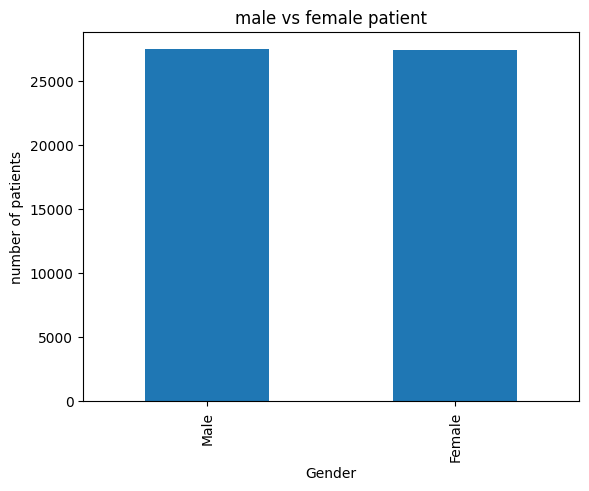

In [41]:
#male female patient ka comparision milega 
df_clean["Gender"].value_counts().plot(kind="bar")
plt.title("male vs female patient")
plt.xlabel("Gender")
plt.ylabel("number of patients")
plt.show()

In [42]:
#medical condition by gender
#ab pata chalega ki har disease me male aur female patients kitne h 


In [43]:
pd.crosstab(
    df_clean["Medical Condition"],
    df_clean["Gender"]
)

Gender,Female,Male
Medical Condition,,
Arthritis,4642,4576
Asthma,4511,4584
Cancer,4566,4574
Diabetes,4609,4607
Hypertension,4569,4582
Obesity,4573,4573


In [44]:
#percentage
pd.crosstab(
    df_clean["Medical Condition"],
    df_clean["Gender"],
    normalize="index"
)*100

Gender,Female,Male
Medical Condition,,
Arthritis,50.357995,49.642005
Asthma,49.598681,50.401319
Cancer,49.956236,50.043764
Diabetes,50.010851,49.989149
Hypertension,49.928970,50.071030
Obesity,50.000000,50.000000


In [45]:
# pd.crosstab() do categories ke beech comparison karta hai.
# Example: Arthritis mein kitne Male aur kitni Female patients hain.

In [46]:
#admission type analysis
# ab check karenge ki patient kis type se hospitsl mein admit hue
df_clean["Admission Type"].value_counts()

Admission Type
Elective     18473
Urgent       18391
Emergency    18102
Name: count, dtype: int64

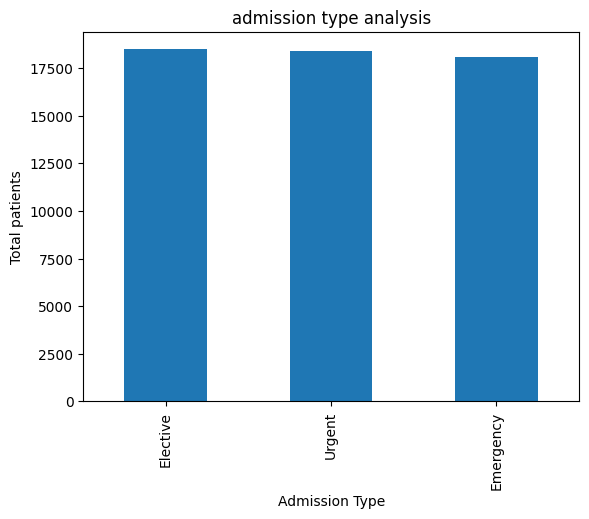

In [47]:
df_clean["Admission Type"].value_counts().plot(kind="bar")

plt.title("admission type analysis")
plt.xlabel("Admission Type")
plt.ylabel("Total patients")
plt.show()

In [48]:
# Isse pata chalega ki Emergency, Elective aur Urgent admissions mein kitne patients hain.
# Hospital-wise Patient Analysis
# Ab pata karenge ki kis hospital mein kitne patients admit hue.

In [49]:
df_clean["Hospital"].value_counts().head(10)

Hospital
LLC Smith      44
Ltd Smith      39
Smith Ltd      37
Johnson PLC    37
Smith Group    36
Smith PLC      36
Johnson Inc    34
Smith Inc      33
Group Smith    32
Smith LLC      32
Name: count, dtype: int64

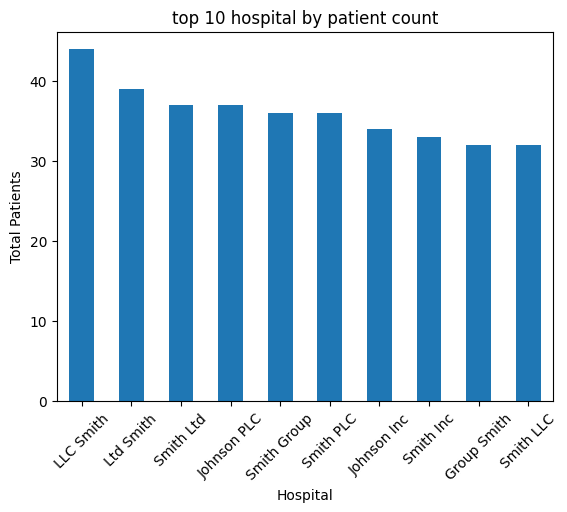

In [50]:
df_clean["Hospital"].value_counts().head(10).plot(kind="bar")

plt.title("top 10 hospital by patient count")
plt.xlabel("Hospital")
plt.ylabel("Total Patients")
plt.xticks(rotation=45)
plt.show()

In [51]:
# Insurance Provider Analysis
# Ab check karenge ki kis insurance company ke kitne patients hain.

In [52]:
df_clean["Insurance Provider"].value_counts()

Insurance Provider
Cigna               11139
Medicare            11039
UnitedHealthcare    11014
Blue Cross          10952
Aetna               10822
Name: count, dtype: int64

In [53]:
#Top 5 Insurance Providers:
df_clean["Insurance Provider"].value_counts().head(5)


Insurance Provider
Cigna               11139
Medicare            11039
UnitedHealthcare    11014
Blue Cross          10952
Aetna               10822
Name: count, dtype: int64

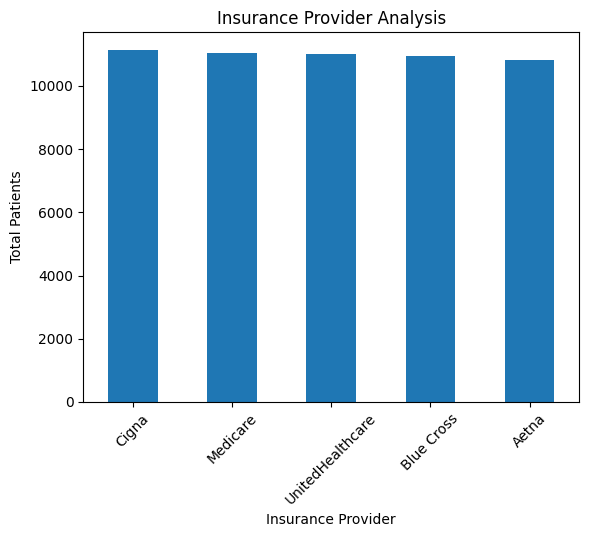

In [54]:
df_clean["Insurance Provider"].value_counts().head(10).plot(kind="bar")

plt.title("Insurance Provider Analysis")
plt.xlabel("Insurance Provider")
plt.ylabel("Total Patients")
plt.xticks(rotation=45)
plt.show()

In [55]:
#total billing amt
df_clean["Billing Amount"].sum()

np.float64(1404068339.227449)

In [56]:
#avg billing amt
df_clean["Billing Amount"].mean()

np.float64(25544.306284383965)

In [57]:
#maximum aur minimum bill
print("Minimum:", df_clean["Billing Amount"].min())
print("Maximum:", df_clean["Billing Amount"].max())

Minimum: -2008.4921398591305
Maximum: 52764.276736469175


In [58]:
#medical condition-wise avg bill
df_clean.groupby("Medical Condition")["Billing Amount"].mean().sort_values(ascending=False)

Medical Condition
Obesity         25804.361902
Diabetes        25660.478635
Asthma          25633.461696
Arthritis       25511.783246
Hypertension    25503.058720
Cancer          25152.322947
Name: Billing Amount, dtype: float64

In [59]:
#sirf heighest condition dekhne ke liye :
df_clean.groupby("Medical Condition")["Billing Amount"].mean().idxmax()

'Obesity'

In [60]:
#avg  bill
df_clean.groupby("Medical Condition")["Billing Amount"].mean().max()

np.float64(25804.361901759086)

In [61]:
# : Medical Condition-wise Total Revenue
# kis disease se hospital ko total billing sabse zyada hui.

In [62]:
df_clean.groupby("Medical Condition")["Billing Amount"].sum().sort_values(ascending=False)

Medical Condition
Diabetes        2.364870e+08
Obesity         2.360067e+08
Arthritis       2.351676e+08
Hypertension    2.333785e+08
Asthma          2.331363e+08
Cancer          2.298922e+08
Name: Billing Amount, dtype: float64

In [63]:
#admission type_wise avg billing 
# Ab pata karenge ki Emergency, Elective aur Urgent admission mein kis type ka average bill sabse 
# zyada hai.

In [64]:
df_clean.groupby("Admission Type")["Billing Amount"].sum().sort_values(ascending=False)

Admission Type
Elective     4.731331e+08
Urgent       4.692378e+08
Emergency    4.616975e+08
Name: Billing Amount, dtype: float64

In [65]:
#kis admission mein paitient ka avg billing amt sabse zada hai

In [66]:
# Length of Hospital Stay
# Ab calculate karenge ki patients average kitne din hospital mein rahe.
# New Column Create karo:

In [67]:
df_clean["Stay Days"] = (
    df_clean["Discharge Date"] - df_clean["Date of Admission"]
).dt.days

In [68]:
# avg hospital stay.:
df_clean["Stay Days"].mean()

np.float64(15.499290470472657)

In [69]:
# medical condition wise avg stay
df_clean.groupby("Medical Condition")["Stay Days"].sum().sort_values(ascending=False)

Medical Condition
Arthritis       142918
Asthma          142585
Diabetes        142209
Cancer          141681
Obesity         141284
Hypertension    141257
Name: Stay Days, dtype: int64

In [70]:
# Medication Analysis
# Ab check karenge ki hospital mein kaunsi medicines sabse zyada prescribe hui hain.

In [71]:
#medicine wise patient count 
df_clean["Medication"].value_counts()

Medication
Lipitor        11038
Ibuprofen      11023
Aspirin        10984
Paracetamol    10965
Penicillin     10956
Name: count, dtype: int64

In [72]:
#top 5 medicines
df_clean["Medication"].value_counts().head(5)

Medication
Lipitor        11038
Ibuprofen      11023
Aspirin        10984
Paracetamol    10965
Penicillin     10956
Name: count, dtype: int64

In [73]:
df_clean["Medication"].value_counts().idxmax()

'Lipitor'

In [74]:
df_clean["Medication"].value_counts().max()

np.int64(11038)

In [75]:
# Test Results Analysis
# Ab check karenge ki kitne patients ke test results Normal, Abnormal aur Inconclusive aaye.

In [76]:
#counting
df_clean["Test Results"].value_counts()

Test Results
Abnormal        18437
Normal          18331
Inconclusive    18198
Name: count, dtype: int64

In [77]:
#pecentage
df_clean["Test Results"].value_counts(normalize=True)*100

Test Results
Abnormal        33.542554
Normal          33.349707
Inconclusive    33.107739
Name: proportion, dtype: float64

In [78]:
df_clean["Test Results"].value_counts().idxmax()

'Abnormal'

In [79]:
#uski total counting:
df_clean["Test Results"].value_counts().max()

np.int64(18437)

In [80]:
# Correlation Analysis
# Ab check karenge ki Age aur Billing Amount ke beech koi relationship hai ya nahi.

In [81]:
df_clean[["Age","Billing Amount","Stay Days"]].corr()

,Age,Billing Amount,Stay Days
Age,1.000000,-0.003427,0.007890
Billing Amount,-0.003427,1.000000,-0.004891
Stay Days,0.007890,-0.004891,1.000000


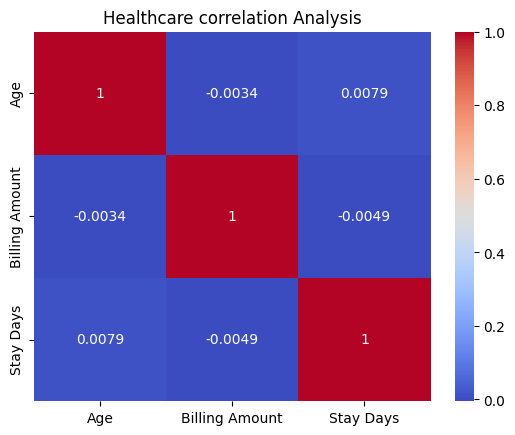

In [82]:
sns.heatmap(
    df_clean[["Age","Billing Amount","Stay Days"]].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Healthcare correlation Analysis")
plt.show()

In [83]:
# Correlation Analysis kya hai?
# Correlation ka matlab hai: Do columns ke beech relationship check karna.
# Hum Healthcare Project mein 3 columns compare kar rahe hain:
# Age
# Billing Amount
# Stay Days
# Correlation Calculate karna
# df_clean[["Age", "Billing Amount", "Stay Days"]].corr()
# f_clean – Hamara dataset.
# [["Age", "Billing Amount", "Stay Days"]] – Ye 3 columns select kiye.
# corr() – Inke beech relationship calculate karta ha
# ---------------------------------Correlation ki value hamesha -1 se +1 ke beech hoti hai.----
# Value	Meaning
# +1	Strong Positive Relationship
# 0	No Linear Relationship
# -1	Strong Negative Relationship

# 2. Heatmap banana
# sns.heatmap(
#     df_clean[["Age", "Billing Amount", "Stay Days"]].corr(),
#     annot=True,
#     cmap="coolwarm"
# )
# sns.heatmap() – Correlation ko graphical form mein dikhata hai.
# annot=True – Boxes ke andar numerical values dikhata hai.
# cmap="coolwarm" – Colours set karta hai.
# 1 = Strong Positive Relationship
# -1 = Strong Negative Relationship
# 0 = Almost No Linear Relationship
# Outlier Analysis – Billing Amount
# Ab check karenge ki billing mein unusually high ya low values hain ya nahi.

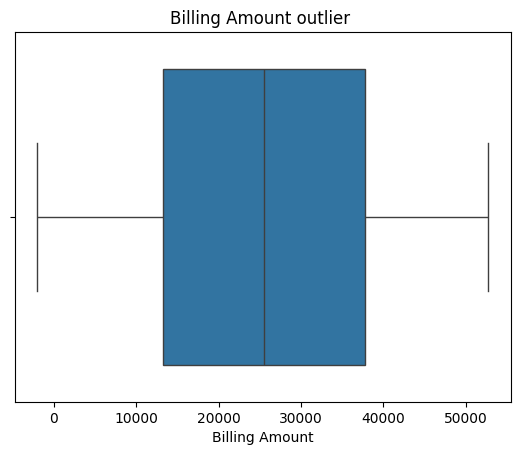

In [84]:
sns.boxplot(x=df_clean["Billing Amount"])
plt.title("Billing Amount outlier ")
plt.show()

In [85]:
df_clean["Billing Amount"].describe()

count    54966.000000
mean     25544.306284
std      14208.409711
min      -2008.492140
25%      13243.718641
50%      25542.749145
75%      37819.858159
max      52764.276736
Name: Billing Amount, dtype: float64

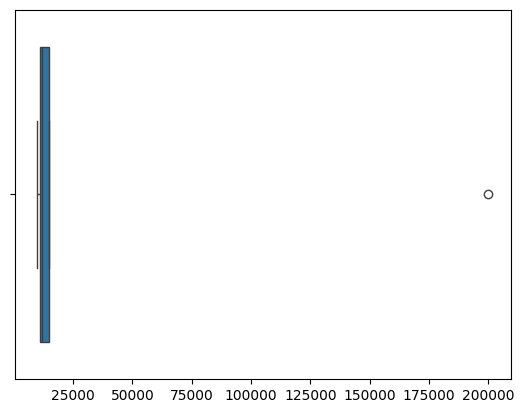

count    54966.000000
mean     25544.306284
std      14208.409711
min      -2008.492140
25%      13243.718641
50%      25542.749145
75%      37819.858159
max      52764.276736
Name: Billing Amount, dtype: float64

In [86]:
# Outlier kya hota hai?
# Maan lo 5 patients ke hospital bills hain:
billing = [10000, 12000, 15000, 11000, 200000]
# Yahan ₹2,00,000 baaki bills se bahut zyada hai. Ye ek potential outlier hai.
sns.boxplot(x=billing)
plt.show()
# Boxplot data mein unusual values ko visually identify karne mein help karta hai.
# Box: Beech ke 50% data ko dikhata hai.
# Middle line: Median.
# Whiskers: Normal range ka approximate spread.
# Bahar ke dots: Potential outliers.
df_clean["Billing Amount"].describe()
# Mean: Average bill
# Min: Sabse chhota bill
# Max: Sabse bada bill
# 25%, 50%, 75%: Data ke quartiles

# Project mein iska use
# Hum identify karenge ki healthcare dataset mein kuch patients ke bills unusually high ya
# low toh nahi hain.

# Important: Outlier ka matlab galat data nahi hota. Use remove karne se pehle investigate 
# karna chahiye.

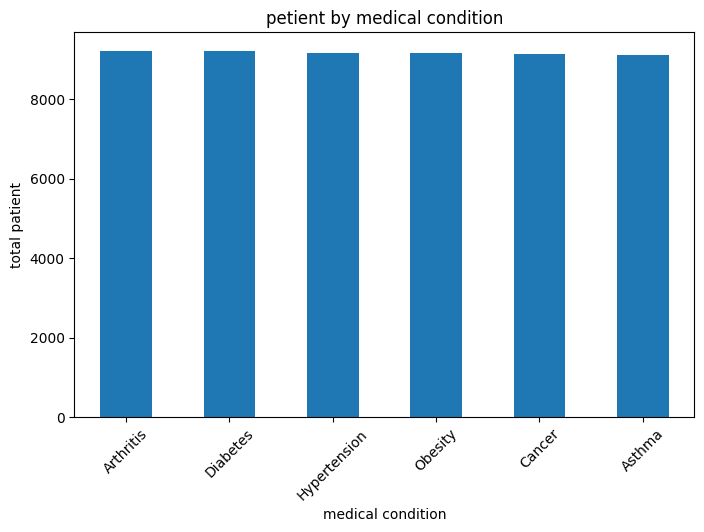

In [87]:
df_clean["Medical Condition"].value_counts().plot(
    kind="bar",
    figsize=(8,5)
)
plt.title("petient by medical condition")
plt.xlabel("medical condition")
plt.ylabel("total patient")
plt.xticks(rotation=45)
plt.show()

In [88]:
# Is chart se pata chalega ki kaunsi disease ke patients sabse zyada hain.

In [89]:
# Age Group Analysis Chart
# Ab dekhenge kis age group ke sabse zyada patients hain.

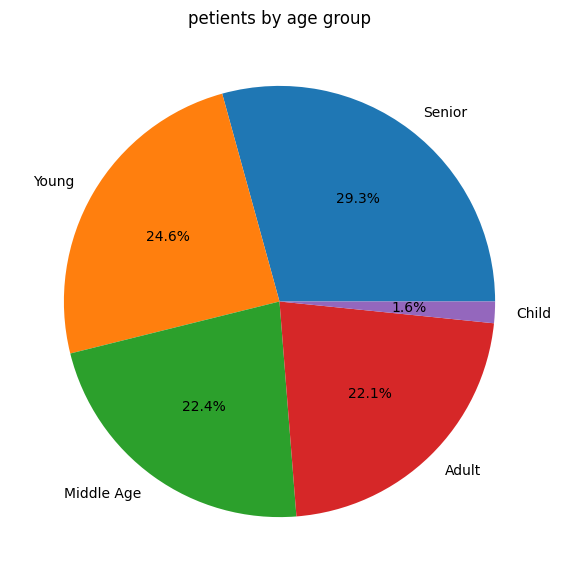

In [90]:
df_clean["Age Group"].value_counts().plot(
    kind="pie",
autopct="%1.1f%%",
figsize=(7,7)
)

plt.title("petients by age group")
plt.ylabel("")
plt.show()

In [91]:
#monthly patient admission ananlysiis
#ab check karenge ki kis month me sabse zada patient admit hue h 

In [92]:
#month col banana
df_clean["Month"] = df_clean["Date of Admission"].dt.month_name()

In [93]:
#monthly column banao:
df_clean["Month"].value_counts()

Month
August       4785
July         4765
January      4655
June         4650
March        4622
December     4617
October      4613
May          4555
November     4508
September    4508
April        4478
February     4210
Name: count, dtype: int64

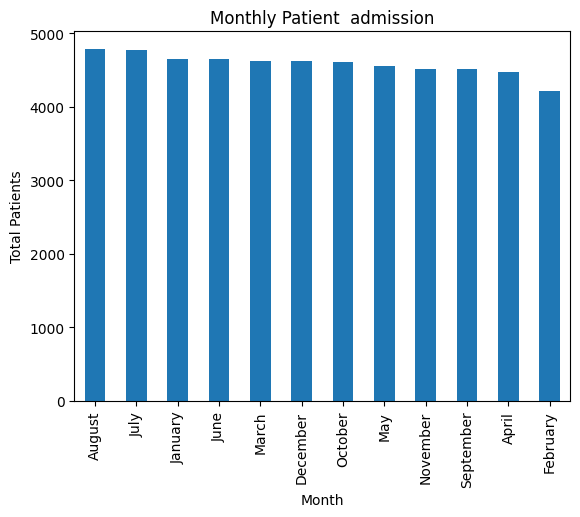

In [94]:
df_clean["Month"].value_counts().plot(kind="bar")
plt.title("Monthly Patient  admission")
plt.xlabel("Month")
plt.ylabel("Total Patients")
plt.show()

In [95]:
# Admission Type vs Billing Analysis
# Ab check karenge ki kis admission type ka total billing amount sabse zyada hai.

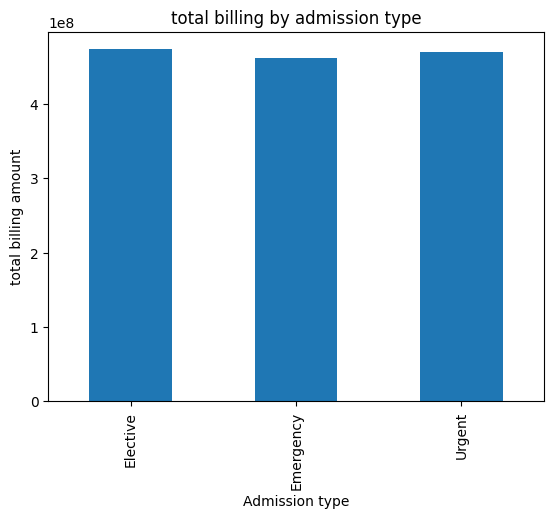

In [96]:
df_clean.groupby("Admission Type")["Billing Amount"].sum().plot(kind="bar")

plt.title("total billing by admission type")
plt.xlabel("Admission type")
plt.ylabel("total billing amount")
plt.show()

In [97]:
# Project Insight: Emergency, Elective aur Urgent mein kis category 
# se sabse zyada billing hui?

In [98]:
# Final Project Summary
# Ab apne project ke important KPIs calculate karenge.

In [99]:
print("Total patient :",len(df_clean))

print("Avg age:",round(df_clean["Age"].mean(),2))

print("Avg billing:",round(df_clean["Billing Amount"].mean(),2))

print("total billing:",round(df_clean["Billing Amount"].sum(),2))

print("Avg hospital stay:",round(df_clean["Stay Days"].mean(),2))

print("total hospitals:",df_clean["Hospital"].nunique())

Total patient : 54966
Avg age: 51.54
Avg billing: 25544.31
total billing: 1404068339.23
Avg hospital stay: 15.5
total hospitals: 39876


In [100]:
# Final Project Report
# Ab ek final report banayenge jisme project ke important findings honge.

In [101]:
print("HEALTHCARE DATA ANALYSIS REPORT")
print("--------------------------------")

print("Total Patients:", len(df_clean))

print("Top Medical Condition:",
      df_clean["Medical Condition"].value_counts().idxmax())

print("Highest Average Billing Condition:",
      df_clean.groupby("Medical Condition")["Billing Amount"].mean().idxmax())

print("Most Prescribed Medicine:",
      df_clean["Medication"].value_counts().idxmax())

print("Most Common Test Result:",
      df_clean["Test Results"].value_counts().idxmax())

HEALTHCARE DATA ANALYSIS REPORT
--------------------------------
Total Patients: 54966
Top Medical Condition: Arthritis
Highest Average Billing Condition: Obesity
Most Prescribed Medicine: Lipitor
Most Common Test Result: Abnormal


In [102]:
# Cleaned Dataset Export karna
# Ab cleaned data ko CSV file mein save karenge.

In [105]:
df_clean.to_csv("healthcare_cleaned.csv",index=False)
print("cleaned data is successfully saved ")

cleaned data is successfully saved 


In [106]:
!git add healthcare_new.ipynb healthcare_dataset.csv

In [107]:
!git commit -m "First commit"

[main e3240ff] First commit
 2 files changed, 58345 insertions(+)
 create mode 100644 EDA/healthcare_dataset.csv
 create mode 100644 EDA/healthcare_new.ipynb


In [108]:
!git push -u origin main

branch 'main' set up to track 'origin/main'.


To https://github.com/ishikaax05/EDA-PROJECT.git
   8a9ceda..e3240ff  main -> main
